In [6]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving zika.xlsx to zika.xlsx


In [7]:
import pandas as pd

data = pd.read_excel('zika.xlsx')

data

,ID,Name,Marks in Quiz\n (Out of 100),Mid Term Results (Out of 100),Final Term Resul (Out of 100),Final Score,Grade
0,2455301209,Zika Dwi Alya Putri,89,90,92,90.00,A
1,120005,Jane Smith,86,80,94,90.00,A
2,120017,Michael Johnson,50,60,88,66.60,B
3,120018,Emily Brown,85,80,90,85.10,A
4,120022,Daniel Martinez,72,85,80,79.09,AB
5,120024,Sarah Wilson,85,75,70,76.45,AB
6,120025,David Garcia,70,70,80,73.50,B
7,120027,Jessica Lee,95,91,90,91.93,A
8,120034,Matthew Davis,79,84,80,81.00,A
9,120035,Jennifer Rodriguez,42,48,63,51.33,C


In [8]:
print("Jumlah data :", len(data))
print("Jumlah kolom:", len(data.columns))

data.info()

Jumlah data : 30
Jumlah kolom: 7
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   ID                              30 non-null     int64  
 1   Name                            30 non-null     object 
 2   Marks in Quiz
 (Out of 100)     30 non-null     int64  
 3   Mid Term Results (Out of 100)   30 non-null     int64  
 4   Final Term Resul  (Out of 100)  30 non-null     int64  
 5   Final Score                     30 non-null     float64
 6   Grade                           30 non-null     object 
dtypes: float64(1), int64(4), object(2)
memory usage: 1.8+ KB


In [10]:
frekuensi = data['Grade'].value_counts()
print("Tabel Frekuensi Grade")
frekuensi

Tabel Frekuensi Grade


,count
Grade,
A,14
B,5
AB,5
C,4
F,1
BC,1


In [11]:
tabel_frekuensi = data['Grade'].value_counts().reset_index()
tabel_frekuensi.columns = ['Grade', 'Frekuensi']
tabel_frekuensi['Persentase'] = (
    tabel_frekuensi['Frekuensi'] / len(data) * 100
).round(2)
tabel_frekuensi

,Grade,Frekuensi,Persentase
0,A,14,46.67
1,B,5,16.67
2,AB,5,16.67
3,C,4,13.33
4,F,1,3.33
5,BC,1,3.33


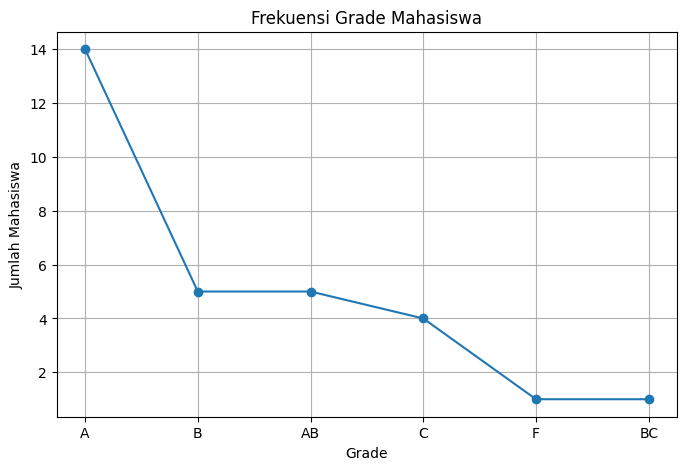

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(
    tabel_frekuensi['Grade'],
    tabel_frekuensi['Frekuensi'],
    marker='o')

plt.title('Frekuensi Grade Mahasiswa')
plt.xlabel('Grade')
plt.ylabel('Jumlah Mahasiswa')
plt.grid(True)

plt.show()

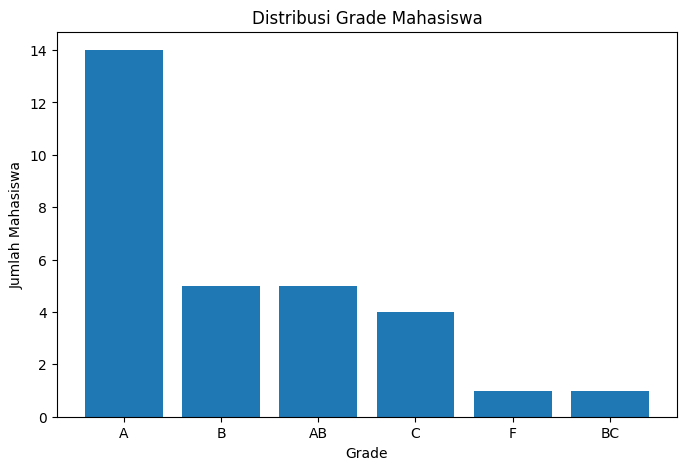

In [13]:
plt.figure(figsize=(8, 5))
plt.bar(
    tabel_frekuensi['Grade'],
    tabel_frekuensi['Frekuensi']
)

plt.title('Distribusi Grade Mahasiswa')
plt.xlabel('Grade')
plt.ylabel('Jumlah Mahasiswa')
plt.show()

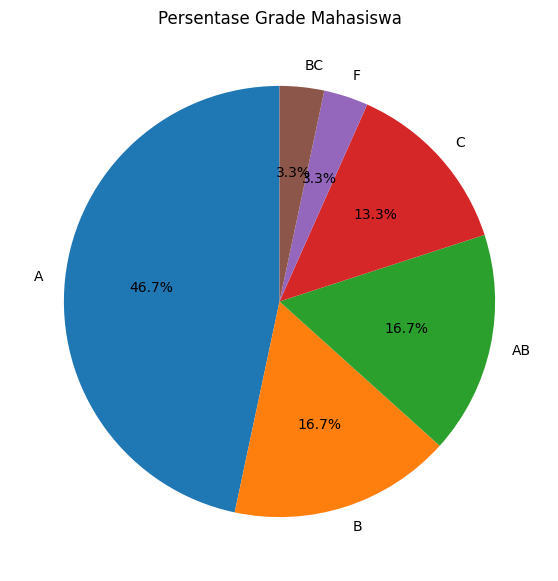

In [14]:
plt.figure(figsize=(7, 7))
plt.pie(
    tabel_frekuensi['Frekuensi'],
    labels=tabel_frekuensi['Grade'],
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Persentase Grade Mahasiswa')

plt.show()

In [15]:
nilai = data['Final Score']

print("STATISTIKA DESKRIPTIF FINAL SCORE")
print("--------------------------------")

print("Mean       :", nilai.mean())
print("Median     :", nilai.median())
print("Modus      :", nilai.mode().tolist())
print("Minimum    :", nilai.min())
print("Maximum    :", nilai.max())
print("Variance   :", nilai.var())
print("Std Deviasi:", nilai.std())
print("Skewness   :", nilai.skew())
print("Kurtosis   :", nilai.kurt())

STATISTIKA DESKRIPTIF FINAL SCORE
--------------------------------
Mean       : 76.562
Median     : 79.195
Modus      : [90.0]
Minimum    : 46.01000000000001
Maximum    : 92.7
Variance   : 173.11976137931035
Std Deviasi: 13.15749829486253
Skewness   : -0.6920462871257648
Kurtosis   : -0.40934382521164636


In [16]:
q1 = nilai.quantile(0.25)
q2 = nilai.quantile(0.50)
q3 = nilai.quantile(0.75)

print("Q1 =", q1)
print("Q2 =", q2)
print("Q3 =", q3)

Q1 = 68.05250000000001
Q2 = 79.195
Q3 = 89.05


In [17]:
iqr = q3 - q1
batas_bawah = q1 - (1.5 * iqr)
batas_atas = q3 + (1.5 * iqr)

print("IQR         :", iqr)
print("Batas bawah :", batas_bawah)
print("Batas atas  :", batas_atas)

IQR         : 20.997499999999988
Batas bawah : 36.55625000000003
Batas atas  : 120.54624999999999


In [19]:
standard_error = nilai.std() / (len(nilai) ** 0.5)
print("Standard Error =", standard_error)

Standard Error = 2.4022195388106558


In [20]:
statistik = pd.DataFrame({
    'Statistik': [
        'Mean',
        'Median',
        'Modus',
        'Minimum',
        'Maximum',
        'Q1',
        'Q2',
        'Q3',
        'IQR',
        'Variance',
        'Standard Deviation',
        'Skewness',
        'Kurtosis',
        'Standard Error'
    ],
    'Nilai': [
        nilai.mean(),
        nilai.median(),
        nilai.mode().iloc[0],
        nilai.min(),
        nilai.max(),
        q1,
        q2,
        q3,
        iqr,
        nilai.var(),
        nilai.std(),
        nilai.skew(),
        nilai.kurt(),
        standard_error
    ]
})
statistik

,Statistik,Nilai
0,Mean,76.562000
1,Median,79.195000
2,Modus,90.000000
3,Minimum,46.010000
4,Maximum,92.700000
5,Q1,68.052500
6,Q2,79.195000
7,Q3,89.050000
8,IQR,20.997500
9,Variance,173.119761
